# 05 - Ek Analizler
Modeli bir **karar aracına** dönüştüren ve sonuçların güvenilirliğini test eden üç analiz.
*Önce 02 numaralı defteri veya `python main.py` çalıştırın (kaydedilen modelleri kullanır).*

1. **Senaryo (ne olur?) analizi:** Model 'memnun değil' dediği yolcularda bir hizmetin puanı
   1 artarsa kaç yolcuyu 'memnun'a çeviriyor?
2. **Hata analizi:** Model kimi yanlış tahmin ediyor?
3. **McNemar testi:** Random Forest, Decision Tree'den istatistiksel olarak anlamlı biçimde iyi mi?

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import analysis, data_loader
from src import config as C
from src import visualization as viz
from src.preprocessing import split_xy

viz.set_style()
pd.set_option("display.max_columns", 30)

In [2]:
_, test = data_loader.load_data()
X_test, y_test = split_xy(test)
rf = joblib.load(C.MODEL_DIR / "random_forest.joblib")
dt = joblib.load(C.MODEL_DIR / "decision_tree.joblib")

## 1. Senaryo analizi
> Bu bir **nedensellik iddiası değildir**: modelin öğrendiği ilişkiye göre bir öngörüdür. Gerçek yatırım kararı için kontrollü deney (A/B testi) gerekir.

Model 'memnun değil' dediği yolcu: 14935


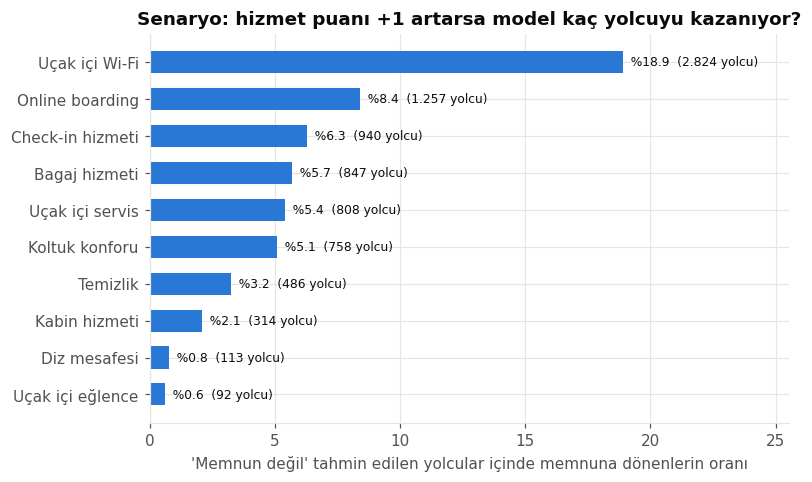

,hizmet,sutun,uygun_yolcu,memnuna_donen,donusum_%,uygunlar_icinde_%,ort_olasilik_artisi
0,Uçak içi Wi-Fi,inflight_wifi,14908,2824,18.91,18.94,0.1920
1,Online boarding,online_boarding,13920,1257,8.42,9.03,0.0905
2,Check-in hizmeti,checkin_service,12874,940,6.29,7.30,0.0558
3,Bagaj hizmeti,baggage_handling,12399,847,5.67,6.83,0.0568
4,Uçak içi servis,inflight_service,12212,808,5.41,6.62,0.0550
5,Koltuk konforu,seat_comfort,12590,758,5.08,6.02,0.0463
6,Temizlik,cleanliness,12756,486,3.25,3.81,0.0300
7,Kabin hizmeti,onboard_service,12914,314,2.10,2.43,0.0245
8,Diz mesafesi,leg_room,12398,113,0.76,0.91,0.0136
9,Uçak içi eğlence,inflight_entertainment,12743,92,0.62,0.72,0.0194


In [3]:
wi = analysis.what_if(rf, X_test)
print("Model 'memnun değil' dediği yolcu:", wi.attrs["memnun_degil_tahmini"])
analysis.plot_what_if(wi)
plt.show()
wi

In [4]:
analysis.what_if_by_class(rf, X_test)

,sinif,sira,hizmet,donusum_%,memnuna_donen
0,Economy,1,Uçak içi Wi-Fi,18.67,1810
1,Economy,2,Bagaj hizmeti,4.88,473
2,Economy,3,Uçak içi servis,4.69,455
3,Economy,4,Check-in hizmeti,3.70,359
4,Economy,5,Online boarding,3.46,335
5,Business,1,Online boarding,22.12,832
6,Business,2,Uçak içi Wi-Fi,21.06,792
7,Business,3,Check-in hizmeti,12.79,481
8,Business,4,Koltuk konforu,11.83,445
9,Business,5,Temizlik,8.30,312


## 2. Hata analizi

{
  "test_yolcu": 25976,
  "hatali_tahmin": 916,
  "hata_orani_%": 3.53,
  "yanlis_pozitif": 277,
  "yanlis_negatif": 639,
  "hatalarin_sinirda_%": 39.08,
  "dogrularin_sinirda_%": 2.4
}


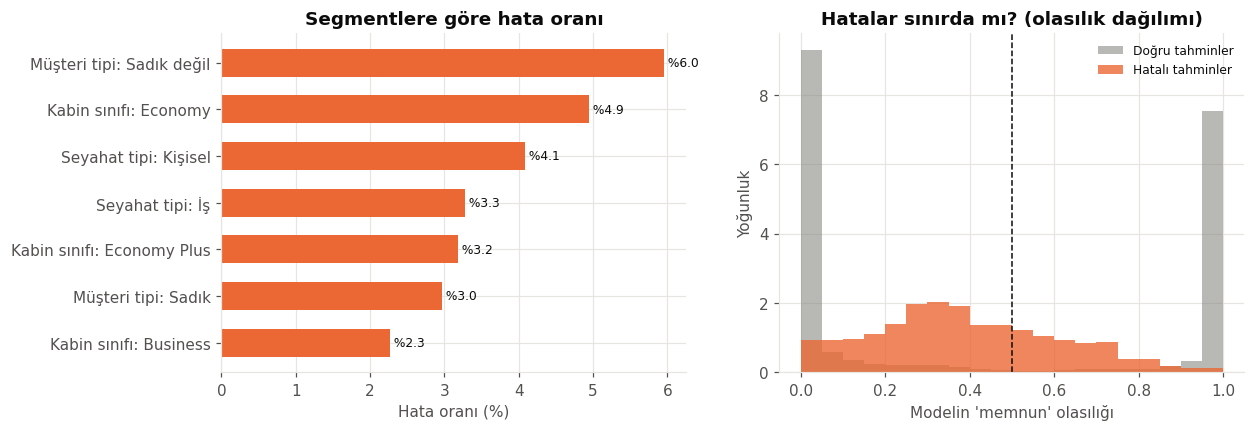

,degisken,deger,yolcu,hata_%
0,Kabin sınıfı,Business,12495,2.27
1,Kabin sınıfı,Economy,11564,4.94
2,Kabin sınıfı,Economy Plus,1917,3.18
3,Seyahat tipi,Kişisel,7938,4.09
4,Seyahat tipi,İş,18038,3.28
5,Müşteri tipi,Sadık,21177,2.97
6,Müşteri tipi,Sadık değil,4799,5.96


_tur,Doğru,Yanlış negatif,Yanlış pozitif
Uçak içi Wi-Fi,2.69,3.70,3.88
Kalkış/varış saati uygunluğu,3.04,3.26,3.22
Online rezervasyon kolaylığı,2.73,3.49,3.65
Kapı konumu,2.98,2.89,3.03
Yiyecek-içecek,3.22,3.06,3.41
Online boarding,3.25,3.54,3.71
Koltuk konforu,3.46,3.11,3.34
Uçak içi eğlence,3.36,3.05,3.51
Kabin hizmeti,3.39,3.16,3.49
Diz mesafesi,3.35,3.23,3.52


In [5]:
summ, segments, profile, df = analysis.error_analysis(rf, X_test, y_test)
print(json.dumps(summ, indent=2, ensure_ascii=False))
analysis.plot_errors(segments, df)
plt.show()
display(segments, profile)

## 3. McNemar testi
İki model aynı test yolcularında değerlendirilir. Yalnızca birinin doğru bildiği yolcular sayılır; fark tesadüfse bu iki sayı birbirine yakın olmalıdır.

In [6]:
analysis.mcnemar_test(rf, dt, X_test, y_test)

{'model_a': 'Random Forest',
 'model_b': 'Decision Tree',
 'a_dogru_b_yanlis': 448,
 'a_yanlis_b_dogru': 176,
 'istatistik': 117.694,
 'p_degeri': 2.0232074930474283e-27,
 'yontem': 'chi-square (continuity corrected)',
 'dogruluk_farki': 0.0105,
 'fark_%95_GA': [0.0086, 0.0123],
 'anlamli_mi_(p<0.05)': True}

## Yorum
- **Senaryo:** RF, test setindeki 25.976 yolcudan 14.935'ini "memnun değil" tahmin ediyor. Wi-Fi
  puanı +1 artırıldığında bunların 2.824'ü (%18,91) memnuna dönüyor; ardından online boarding
  (1.257 yolcu, %8,42) ve check-in hizmeti (940 yolcu, %6,29) geliyor.
- Öncelik segmente göre değişiyor: Economy'de Wi-Fi (%18,67) açık ara birinci, bagaj hizmeti
  (%4,88) ikinci; Business'ta online boarding (%22,12) ve Wi-Fi (%21,06) başta, check-in (%12,79)
  ve koltuk konforu (%11,83) ardından geliyor.
- Bu sonuçlar modelin öngörüsüdür, nedensel etki değildir; yatırım kararı için A/B testi gerekir.
- **Hata analizi:** 916 hatalı tahmin (%3,53): 639 yanlış negatif, 277 yanlış pozitif; bu durum
  precision'ın recall'dan yüksek olmasıyla tutarlı. Hataların %39,08'i modelin kararsız olduğu
  0,35–0,65 olasılık aralığında; doğru tahminlerde bu oran %2,40. Hata oranı sadık olmayan
  müşterilerde (%5,96) ve Economy'de (%4,94) en yüksek, Business'ta en düşük (%2,27).
- **McNemar:** RF'nin doğru, DT'nin yanlış bildiği 448 yolcuya karşılık tersi 176 yolcu;
  χ² = 117,69, p ≈ 2,0 × 10⁻²⁷. Doğruluk farkı 0,0105 ve bootstrap %95 GA [0,0086; 0,0123] sıfırı
  içermiyor: RF'nin üstünlüğü istatistiksel olarak anlamlı.